In [ ]:
# ==========================================================================
# INSTALAÇÃO
# ==========================================================================
!pip install -q librosa soundfile matplotlib pandas

# ==========================================================================
# IMPORTS
# ==========================================================================
import os, zipfile
import numpy as np
import librosa
import librosa.display
import soundfile as sf
import matplotlib.pyplot as plt
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers, models
from google.colab import files

# ==========================================================================
# CONFIGURAÇÕES
# ==========================================================================
SR = 16000
DURACAO_SEG = 2.0
SEG_LEN = int(SR * DURACAO_SEG)
RMS_ALVO = 0.1
EPS = 1e-10

OUT_DIR = "/content/denoised"
os.makedirs(OUT_DIR, exist_ok=True)

# ==========================================================================
# 1. UPLOAD DO MODELO CNN TREINADO
# ==========================================================================
print(">>> Faça upload do MODELO CNN treinado (.keras)")
uploaded_model = files.upload()
model_filename = list(uploaded_model.keys())[0]
with open(model_filename, 'wb') as f:
    f.write(uploaded_model[model_filename])
print(f"Modelo recebido: {model_filename}")

# ==========================================================================
# 2. UPLOAD DOS ÁUDIOS RUIDOSOS
# ==========================================================================
print("\n>>> Faça upload dos áudios RUIDOSOS (.wav)")
uploaded_noisy = files.upload()
noisy_files = list(uploaded_noisy.keys())
print("Áudios ruidosos:", noisy_files)

# ==========================================================================
# 3. UPLOAD DOS ÁUDIOS LIMPOS (referência)
# ==========================================================================
print("\n>>> Faça upload dos áudios LIMPOS de referência (.wav)")
uploaded_clean = files.upload()
clean_files = list(uploaded_clean.keys())
print("Áudios limpos:", clean_files)

# ==========================================================================
# ARQUITETURA CNN 1D (U-NET 1D) — idêntica à do treino
# ==========================================================================
def build_cnn1d_denoiser(input_len=SEG_LEN):
    inputs = layers.Input(shape=(input_len, 1))
    c1 = layers.Conv1D(32, 15, padding='same', activation='relu')(inputs)
    c1 = layers.Conv1D(32, 15, padding='same', activation='relu')(c1)
    p1 = layers.MaxPool1D(2)(c1)
    c2 = layers.Conv1D(64, 11, padding='same', activation='relu')(p1)
    c2 = layers.Conv1D(64, 11, padding='same', activation='relu')(c2)
    p2 = layers.MaxPool1D(2)(c2)
    c3 = layers.Conv1D(128, 9, padding='same', activation='relu')(p2)
    c3 = layers.Conv1D(128, 9, padding='same', activation='relu')(c3)
    p3 = layers.MaxPool1D(2)(c3)
    c4 = layers.Conv1D(256, 7, padding='same', activation='relu')(p3)
    c4 = layers.Conv1D(256, 7, padding='same', activation='relu')(c4)
    p4 = layers.MaxPool1D(2)(c4)
    c5 = layers.Conv1D(512, 5, padding='same', activation='relu')(p4)
    c5 = layers.Conv1D(512, 5, padding='same', activation='relu')(c5)
    u6 = layers.UpSampling1D(2)(c5); u6 = layers.Concatenate()([u6, c4])
    c6 = layers.Conv1D(256, 7, padding='same', activation='relu')(u6)
    c6 = layers.Conv1D(256, 7, padding='same', activation='relu')(c6)
    u7 = layers.UpSampling1D(2)(c6); u7 = layers.Concatenate()([u7, c3])
    c7 = layers.Conv1D(128, 9, padding='same', activation='relu')(u7)
    c7 = layers.Conv1D(128, 9, padding='same', activation='relu')(c7)
    u8 = layers.UpSampling1D(2)(c7); u8 = layers.Concatenate()([u8, c2])
    c8 = layers.Conv1D(64, 11, padding='same', activation='relu')(u8)
    c8 = layers.Conv1D(64, 11, padding='same', activation='relu')(c8)
    u9 = layers.UpSampling1D(2)(c8); u9 = layers.Concatenate()([u9, c1])
    c9 = layers.Conv1D(32, 15, padding='same', activation='relu')(u9)
    c9 = layers.Conv1D(32, 15, padding='same', activation='relu')(c9)
    outputs = layers.Conv1D(1, 15, padding='same', activation='linear')(c9)
    return models.Model(inputs, outputs, name="CNN1D_Denoiser")

def custom_loss(y_true, y_pred):
    mse_loss = tf.reduce_mean(tf.square(y_true - y_pred))
    mae_loss = tf.reduce_mean(tf.abs(y_true - y_pred))
    return mse_loss + 0.1 * mae_loss

# ==========================================================================
# CARREGAR O MODELO
# ==========================================================================
print("\n>>> Carregando modelo CNN...")
try:
    model = tf.keras.models.load_model(
        model_filename,
        custom_objects={'custom_loss': custom_loss},
        compile=False)
    model.compile(optimizer='adam', loss=custom_loss)
    print("✅ Modelo carregado com sucesso (.keras completo).")
except Exception as e:
    print(f"Falha ao carregar direto ({e}). Tentando reconstruir a arquitetura...")
    model = build_cnn1d_denoiser()
    model.load_weights(model_filename)
    model.compile(optimizer='adam', loss=custom_loss)
    print("✅ Pesos carregados na arquitetura reconstruída.")

# ==========================================================================
# FUNÇÕES AUXILIARES
# ==========================================================================
def rms(x):
    return float(np.sqrt(np.mean(x ** 2) + EPS))

# ==========================================================================
# DENOISING POR SEGMENTAÇÃO COM A CNN (mesma lógica do treino)
# ==========================================================================
def denoisar_audio_segmentado(limpo_path, ruidoso_path, model,
                              sr=SR, seg_len=SEG_LEN,
                              rms_silencio_db=-35.0, batch_size=32):
    clean_raw, _ = librosa.load(limpo_path, sr=sr, mono=True)
    noisy_raw, _ = librosa.load(ruidoso_path, sr=sr, mono=True)
    n = min(len(clean_raw), len(noisy_raw))
    clean_raw = clean_raw[:n].astype(np.float32)
    noisy_raw = noisy_raw[:n].astype(np.float32)

    pico_noisy = np.max(np.abs(noisy_raw)) + 1e-9
    clean_ref = clean_raw * (0.95 / pico_noisy)
    noisy_ref = noisy_raw * (0.95 / pico_noisy)

    if n < seg_len:
        pad = seg_len - n
        noisy_ref = np.pad(noisy_ref, (0, pad))
        clean_ref = np.pad(clean_ref, (0, pad))
        n_proc = seg_len
    else:
        n_proc = n

    hop = seg_len // 2
    starts = list(range(0, n_proc - seg_len + 1, hop))
    if starts[-1] + seg_len < n_proc:
        starts.append(n_proc - seg_len)

    rms_global = rms(noisy_ref)
    limiar_silencio = rms_global * (10 ** (rms_silencio_db / 20))

    preds = np.zeros((len(starts), seg_len), dtype=np.float32)
    rms_por_janela = np.zeros(len(starts), dtype=np.float32)

    segmentos_norm, indices_validos = [], []
    for i, s in enumerate(starts):
        seg = noisy_ref[s:s + seg_len]
        r = rms(seg)
        if r < limiar_silencio:
            continue
        rms_por_janela[i] = r
        segmentos_norm.append(seg * (RMS_ALVO / (r + 1e-12)))
        indices_validos.append(i)

    if indices_validos:
        X = np.stack(segmentos_norm, axis=0)[..., np.newaxis].astype(np.float32)
        y_pred = model.predict(X, batch_size=batch_size, verbose=0).squeeze(-1)
        y_pred = np.clip(y_pred, -1.0, 1.0)
        for k, idx in enumerate(indices_validos):
            preds[idx] = y_pred[k] * (rms_por_janela[idx] / RMS_ALVO)

    denoised = np.zeros(n_proc, dtype=np.float32)
    window_sum = np.zeros(n_proc, dtype=np.float32)
    window = np.hanning(seg_len).astype(np.float32)

    for i, s in enumerate(starts):
        denoised[s:s + seg_len] += preds[i] * window
        window_sum[s:s + seg_len] += window
    denoised /= (window_sum + 1e-8)

    return clean_ref[:n], noisy_ref[:n], denoised[:n]

# ==========================================================================
# MÉTRICAS
# ==========================================================================
def _align(ref, est):
    n = min(len(ref), len(est))
    return ref[:n], est[:n]

def snr(ref, est):
    ref, est = _align(ref, est)
    noise = ref - est
    num = np.sum(ref ** 2)
    den = np.sum(noise ** 2) + 1e-12
    return 10 * np.log10(num / den)

def snr_seg(ref, est, sr, frame_len=0.02, hop=0.01):
    ref, est = _align(ref, est)
    fl = int(frame_len * sr); hp = int(hop * sr)
    if fl <= 0 or len(ref) < fl:
        return snr(ref, est)
    vals = []
    for s in range(0, len(ref) - fl, hp):
        r = ref[s:s + fl]; e = est[s:s + fl]
        noise = r - e
        num = np.sum(r ** 2); den = np.sum(noise ** 2) + 1e-12
        v = 10 * np.log10(num / den)
        if np.isfinite(v):
            vals.append(v)
    return float(np.mean(vals)) if vals else np.nan

def mse(ref, est):
    ref, est = _align(ref, est)
    return float(np.mean((ref - est) ** 2))

def rmse(ref, est):
    return float(np.sqrt(mse(ref, est)))

def sdr(ref, est):
    ref, est = _align(ref, est)
    ref = ref.astype(np.float64); est = est.astype(np.float64)
    denom = np.dot(ref, ref) + 1e-12
    alpha = np.dot(ref, est) / denom
    s_target = alpha * ref
    e_res = est - s_target
    num = np.sum(s_target ** 2)
    den = np.sum(e_res ** 2) + 1e-12
    return 10 * np.log10(num / den)

def si_sdr(ref, est):
    return sdr(ref, est)

def pearson(ref, est):
    ref, est = _align(ref, est)
    ref = ref.astype(np.float64); est = est.astype(np.float64)
    if np.std(ref) < 1e-12 or np.std(est) < 1e-12:
        return np.nan
    return float(np.corrcoef(ref, est)[0, 1])

# ==========================================================================
# MATCH RUIDOSO ↔ LIMPO
# ==========================================================================
def encontrar_par(noisy_name, clean_files):
    base = noisy_name.rsplit('.', 1)[0]
    candidates = [
        base.replace('chuva', 'limpo'),
        base.replace('ruido', 'limpo'),
        base.replace('ruído', 'limpo'),
        base.replace('_noisy', '_clean'),
        base.replace('_noise', '_clean'),
        base.replace('_n', '_l'),
    ]
    for c in clean_files:
        stem = c.rsplit('.', 1)[0]
        if stem in candidates or stem == base:
            return c
    prefix = base.split('_')[0]
    for c in clean_files:
        if c.rsplit('.', 1)[0].split('_')[0] == prefix:
            return c
    return None

# ==========================================================================
# IMPRESSÃO DA TABELA (formato solicitado)
# ==========================================================================
ORDEM_METRICAS = [
    ("SNR (dB)",      "SNR Ruidoso (dB)",   "SNR CNN (dB)"),
    ("SNRseg (dB)",   "SNRseg Ruidoso (dB)","SNRseg CNN (dB)"),
    ("MSE",           "MSE Ruidoso",        "MSE CNN"),
    ("RMSE",          "RMSE Ruidoso",       "RMSE CNN"),
    ("SDR (dB)",      "SDR Ruidoso (dB)",   "SDR CNN (dB)"),
    ("SI-SDR (dB)",   "SI-SDR Ruidoso (dB)","SI-SDR CNN (dB)"),
    ("Pearson (r)",   "Pearson Ruidoso",    "Pearson CNN"),
]

def _fmt(v):
    if v is None or (isinstance(v, float) and np.isnan(v)):
        return "   nan"
    return f"{v:>10.4f}"

def _fmt_gain(v):
    if v is None or (isinstance(v, float) and np.isnan(v)):
        return "   nan"
    sign = "+" if v >= 0 else "-"
    return f"{sign}{abs(v):>9.4f}"

def imprimir_tabela(titulo, linhas):
    print("\n" + "=" * 80)
    print(titulo)
    print("=" * 80)
    print(f"{'Métrica':<28}{'Ruidoso':>14}{'Processado':>18}{'Ganho':>15}")
    print("=" * 80)
    for nome, r, p in linhas:
        g = (p - r) if (r is not None and p is not None
                        and not (isinstance(r, float) and np.isnan(r))
                        and not (isinstance(p, float) and np.isnan(p))) else np.nan
        print(f"{nome:<28}{_fmt(r):>12}{_fmt(p):>16}{_fmt_gain(g):>15}")
    print("=" * 80)

# ==========================================================================
# PROCESSAMENTO
# ==========================================================================
resultados = []
caminhos_salvos = []

for noisy_name in noisy_files:
    clean_name = encontrar_par(noisy_name, clean_files)
    if clean_name is None:
        print(f"[AVISO] Sem referência limpa para {noisy_name}. Pulando.")
        continue

    print(f"\n>>> Processando: {noisy_name}  (ref: {clean_name})")
    print("    Processando CNN...")

    clean_ref, noisy_ref, den_cnn = denoisar_audio_segmentado(
        clean_name, noisy_name, model)

    n = min(len(clean_ref), len(noisy_ref), len(den_cnn))
    clean_ref = clean_ref[:n]
    noisy_ref = noisy_ref[:n]
    den_cnn   = den_cnn[:n]

    # ----- SALVAR ÁUDIO DENOISED -----
    out_name = noisy_name.rsplit('.', 1)[0] + '_cnn.wav'
    out_path = os.path.join(OUT_DIR, out_name)
    sf.write(out_path, den_cnn, SR)
    caminhos_salvos.append(out_path)
    print(f"    💾 Salvo: {out_path}")

    # ----- MÉTRICAS -----
    row = {
        'Áudio'              : noisy_name,
        'SNR Ruidoso (dB)'   : snr(clean_ref, noisy_ref),
        'SNRseg Ruidoso (dB)': snr_seg(clean_ref, noisy_ref, SR),
        'MSE Ruidoso'        : mse(clean_ref, noisy_ref),
        'RMSE Ruidoso'       : rmse(clean_ref, noisy_ref),
        'SDR Ruidoso (dB)'   : sdr(clean_ref, noisy_ref),
        'SI-SDR Ruidoso (dB)': si_sdr(clean_ref, noisy_ref),
        'Pearson Ruidoso'    : pearson(clean_ref, noisy_ref),
        'SNR CNN (dB)'       : snr(clean_ref, den_cnn),
        'SNRseg CNN (dB)'    : snr_seg(clean_ref, den_cnn, SR),
        'MSE CNN'            : mse(clean_ref, den_cnn),
        'RMSE CNN'           : rmse(clean_ref, den_cnn),
        'SDR CNN (dB)'       : sdr(clean_ref, den_cnn),
        'SI-SDR CNN (dB)'    : si_sdr(clean_ref, den_cnn),
        'Pearson CNN'        : pearson(clean_ref, den_cnn),
    }
    resultados.append(row)

    # ----- TABELA INDIVIDUAL -----
    linhas_individuais = [
        (nome, row[col_r], row[col_p])
        for nome, col_r, col_p in ORDEM_METRICAS
    ]
    imprimir_tabela(f"ÁUDIO: {noisy_name}   (ref: {clean_name}) — CNN", linhas_individuais)

    # ----- GRÁFICO COMPARATIVO (3 espectrogramas) -----
    fig, axes = plt.subplots(3, 1, figsize=(15, 11))

    S_noisy = librosa.amplitude_to_db(np.abs(librosa.stft(noisy_ref)), ref=np.max)
    S_cnn   = librosa.amplitude_to_db(np.abs(librosa.stft(den_cnn)),   ref=np.max)
    S_ref   = librosa.amplitude_to_db(np.abs(librosa.stft(clean_ref)), ref=np.max)

    img0 = librosa.display.specshow(S_noisy, sr=SR, x_axis='time',
                                    y_axis='log', cmap='viridis', ax=axes[0])
    axes[0].set_title(f'Espectrograma — RUIDOSO: {noisy_name}')
    fig.colorbar(img0, ax=axes[0], format='%+2.0f dB')

    img1 = librosa.display.specshow(S_cnn, sr=SR, x_axis='time',
                                    y_axis='log', cmap='viridis', ax=axes[1])
    axes[1].set_title(f'Espectrograma — CNN: {out_name}')
    fig.colorbar(img1, ax=axes[1], format='%+2.0f dB')

    img2 = librosa.display.specshow(S_ref, sr=SR, x_axis='time',
                                    y_axis='log', cmap='viridis', ax=axes[2])
    axes[2].set_title(f'Espectrograma — LIMPO: {clean_name}')
    fig.colorbar(img2, ax=axes[2], format='%+2.0f dB')

    plt.tight_layout()
    plt.show()

    # ----- GRÁFICO DAS FORMAS DE ONDA -----
    fig2, axes2 = plt.subplots(3, 1, figsize=(15, 9))
    axes2[0].plot(clean_ref, linewidth=0.5, color='tab:green')
    axes2[0].set_title(f'Áudio Limpo — SNR ref')
    axes2[1].plot(noisy_ref, linewidth=0.5, color='tab:orange')
    axes2[1].set_title(f'Ruidoso — SNR={row["SNR Ruidoso (dB)"]:.2f} dB')
    axes2[2].plot(den_cnn, linewidth=0.5, color='tab:red')
    axes2[2].set_title(f'CNN — SNR={row["SNR CNN (dB)"]:.2f} dB')
    plt.tight_layout()
    plt.show()

# ==========================================================================
# TABELA FINAL — MÉDIA DE TODOS OS ÁUDIOS
# ==========================================================================
if resultados:
    df = pd.DataFrame(resultados)
    medias = df.drop(columns=['Áudio']).mean()

    linhas_media = [
        (nome, medias[col_r], medias[col_p])
        for nome, col_r, col_p in ORDEM_METRICAS
    ]
    imprimir_tabela(
        f"MÉDIA GERAL — CNN — {len(df)} áudio(s) processado(s)",
        linhas_media
    )

# ==========================================================================
# ZIP + DOWNLOAD
# ==========================================================================
if caminhos_salvos:
    zip_path = "/content/denoised_wavs.zip"
    with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as zf:
        for p in caminhos_salvos:
            zf.write(p, arcname=os.path.basename(p))
    print(f"\n📦 ZIP gerado com {len(caminhos_salvos)} arquivo(s): {zip_path}")
    try:
        files.download(zip_path)
    except Exception as e:
        print(f"[Aviso] Download automático falhou: {e}")
else:
    print("\n[AVISO] Nenhum áudio denoised foi salvo.")

Output hidden; open in https://colab.research.google.com to view.

In [1]:
# ==========================================================================
# INSTALAÇÃO
# ==========================================================================
!pip install -q librosa soundfile matplotlib pandas

# ==========================================================================
# IMPORTS
# ==========================================================================
import os, zipfile
import numpy as np
import librosa
import librosa.display
import soundfile as sf
import matplotlib.pyplot as plt
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers, models
from google.colab import files

# ==========================================================================
# CONFIGURAÇÕES
# ==========================================================================
SR = 16000
DURACAO_SEG = 2.0
SEG_LEN = int(SR * DURACAO_SEG)
RMS_ALVO = 0.1
EPS = 1e-10

OUT_DIR = "/content/denoised"
os.makedirs(OUT_DIR, exist_ok=True)

# ==========================================================================
# 1. UPLOAD DO MODELO CNN TREINADO
# ==========================================================================
print(">>> Faça upload do MODELO CNN treinado (.keras)")
uploaded_model = files.upload()
model_filename = list(uploaded_model.keys())[0]
with open(model_filename, 'wb') as f:
    f.write(uploaded_model[model_filename])
print(f"Modelo recebido: {model_filename}")

# ==========================================================================
# 2. UPLOAD DOS ÁUDIOS RUIDOSOS
# ==========================================================================
print("\n>>> Faça upload dos áudios RUIDOSOS (.wav)")
uploaded_noisy = files.upload()
noisy_files = list(uploaded_noisy.keys())
print("Áudios ruidosos:", noisy_files)

# ==========================================================================
# 3. UPLOAD DOS ÁUDIOS LIMPOS (referência)
# ==========================================================================
print("\n>>> Faça upload dos áudios LIMPOS de referência (.wav)")
uploaded_clean = files.upload()
clean_files = list(uploaded_clean.keys())
print("Áudios limpos:", clean_files)

# ==========================================================================
# ARQUITETURA CNN 1D (U-NET 1D) — idêntica à do treino
# ==========================================================================
def build_cnn1d_denoiser(input_len=SEG_LEN):
    inputs = layers.Input(shape=(input_len, 1))
    c1 = layers.Conv1D(32, 15, padding='same', activation='relu')(inputs)
    c1 = layers.Conv1D(32, 15, padding='same', activation='relu')(c1)
    p1 = layers.MaxPool1D(2)(c1)
    c2 = layers.Conv1D(64, 11, padding='same', activation='relu')(p1)
    c2 = layers.Conv1D(64, 11, padding='same', activation='relu')(c2)
    p2 = layers.MaxPool1D(2)(c2)
    c3 = layers.Conv1D(128, 9, padding='same', activation='relu')(p2)
    c3 = layers.Conv1D(128, 9, padding='same', activation='relu')(c3)
    p3 = layers.MaxPool1D(2)(c3)
    c4 = layers.Conv1D(256, 7, padding='same', activation='relu')(p3)
    c4 = layers.Conv1D(256, 7, padding='same', activation='relu')(c4)
    p4 = layers.MaxPool1D(2)(c4)
    c5 = layers.Conv1D(512, 5, padding='same', activation='relu')(p4)
    c5 = layers.Conv1D(512, 5, padding='same', activation='relu')(c5)
    u6 = layers.UpSampling1D(2)(c5); u6 = layers.Concatenate()([u6, c4])
    c6 = layers.Conv1D(256, 7, padding='same', activation='relu')(u6)
    c6 = layers.Conv1D(256, 7, padding='same', activation='relu')(c6)
    u7 = layers.UpSampling1D(2)(c6); u7 = layers.Concatenate()([u7, c3])
    c7 = layers.Conv1D(128, 9, padding='same', activation='relu')(u7)
    c7 = layers.Conv1D(128, 9, padding='same', activation='relu')(c7)
    u8 = layers.UpSampling1D(2)(c7); u8 = layers.Concatenate()([u8, c2])
    c8 = layers.Conv1D(64, 11, padding='same', activation='relu')(u8)
    c8 = layers.Conv1D(64, 11, padding='same', activation='relu')(c8)
    u9 = layers.UpSampling1D(2)(c8); u9 = layers.Concatenate()([u9, c1])
    c9 = layers.Conv1D(32, 15, padding='same', activation='relu')(u9)
    c9 = layers.Conv1D(32, 15, padding='same', activation='relu')(c9)
    outputs = layers.Conv1D(1, 15, padding='same', activation='linear')(c9)
    return models.Model(inputs, outputs, name="CNN1D_Denoiser")

def custom_loss(y_true, y_pred):
    mse_loss = tf.reduce_mean(tf.square(y_true - y_pred))
    mae_loss = tf.reduce_mean(tf.abs(y_true - y_pred))
    return mse_loss + 0.1 * mae_loss

# ==========================================================================
# CARREGAR O MODELO
# ==========================================================================
print("\n>>> Carregando modelo CNN...")
try:
    model = tf.keras.models.load_model(
        model_filename,
        custom_objects={'custom_loss': custom_loss},
        compile=False)
    model.compile(optimizer='adam', loss=custom_loss)
    print("✅ Modelo carregado com sucesso (.keras completo).")
except Exception as e:
    print(f"Falha ao carregar direto ({e}). Tentando reconstruir a arquitetura...")
    model = build_cnn1d_denoiser()
    model.load_weights(model_filename)
    model.compile(optimizer='adam', loss=custom_loss)
    print("✅ Pesos carregados na arquitetura reconstruída.")

# ==========================================================================
# FUNÇÕES AUXILIARES
# ==========================================================================
def rms(x):
    return float(np.sqrt(np.mean(x ** 2) + EPS))

# ==========================================================================
# DENOISING POR SEGMENTAÇÃO COM A CNN (mesma lógica do treino)
# ==========================================================================
def denoisar_audio_segmentado(limpo_path, ruidoso_path, model,
                              sr=SR, seg_len=SEG_LEN,
                              rms_silencio_db=-35.0, batch_size=32):
    clean_raw, _ = librosa.load(limpo_path, sr=sr, mono=True)
    noisy_raw, _ = librosa.load(ruidoso_path, sr=sr, mono=True)
    n = min(len(clean_raw), len(noisy_raw))
    clean_raw = clean_raw[:n].astype(np.float32)
    noisy_raw = noisy_raw[:n].astype(np.float32)

    pico_noisy = np.max(np.abs(noisy_raw)) + 1e-9
    clean_ref = clean_raw * (0.95 / pico_noisy)
    noisy_ref = noisy_raw * (0.95 / pico_noisy)

    if n < seg_len:
        pad = seg_len - n
        noisy_ref = np.pad(noisy_ref, (0, pad))
        clean_ref = np.pad(clean_ref, (0, pad))
        n_proc = seg_len
    else:
        n_proc = n

    hop = seg_len // 2
    starts = list(range(0, n_proc - seg_len + 1, hop))
    if starts[-1] + seg_len < n_proc:
        starts.append(n_proc - seg_len)

    rms_global = rms(noisy_ref)
    limiar_silencio = rms_global * (10 ** (rms_silencio_db / 20))

    preds = np.zeros((len(starts), seg_len), dtype=np.float32)
    rms_por_janela = np.zeros(len(starts), dtype=np.float32)

    segmentos_norm, indices_validos = [], []
    for i, s in enumerate(starts):
        seg = noisy_ref[s:s + seg_len]
        r = rms(seg)
        if r < limiar_silencio:
            continue
        rms_por_janela[i] = r
        segmentos_norm.append(seg * (RMS_ALVO / (r + 1e-12)))
        indices_validos.append(i)

    if indices_validos:
        X = np.stack(segmentos_norm, axis=0)[..., np.newaxis].astype(np.float32)
        y_pred = model.predict(X, batch_size=batch_size, verbose=0).squeeze(-1)
        y_pred = np.clip(y_pred, -1.0, 1.0)
        for k, idx in enumerate(indices_validos):
            preds[idx] = y_pred[k] * (rms_por_janela[idx] / RMS_ALVO)

    denoised = np.zeros(n_proc, dtype=np.float32)
    window_sum = np.zeros(n_proc, dtype=np.float32)
    window = np.hanning(seg_len).astype(np.float32)

    for i, s in enumerate(starts):
        denoised[s:s + seg_len] += preds[i] * window
        window_sum[s:s + seg_len] += window
    denoised /= (window_sum + 1e-8)

    return clean_ref[:n], noisy_ref[:n], denoised[:n]

# ==========================================================================
# MÉTRICAS
# ==========================================================================
def _align(ref, est):
    n = min(len(ref), len(est))
    return ref[:n], est[:n]

def snr(ref, est):
    ref, est = _align(ref, est)
    noise = ref - est
    num = np.sum(ref ** 2)
    den = np.sum(noise ** 2) + 1e-12
    return 10 * np.log10(num / den)

def snr_seg(ref, est, sr, frame_len=0.02, hop=0.01):
    ref, est = _align(ref, est)
    fl = int(frame_len * sr); hp = int(hop * sr)
    if fl <= 0 or len(ref) < fl:
        return snr(ref, est)
    vals = []
    for s in range(0, len(ref) - fl, hp):
        r = ref[s:s + fl]; e = est[s:s + fl]
        noise = r - e
        num = np.sum(r ** 2); den = np.sum(noise ** 2) + 1e-12
        v = 10 * np.log10(num / den)
        if np.isfinite(v):
            vals.append(v)
    return float(np.mean(vals)) if vals else np.nan

def mse(ref, est):
    ref, est = _align(ref, est)
    return float(np.mean((ref - est) ** 2))

def rmse(ref, est):
    return float(np.sqrt(mse(ref, est)))

def sdr(ref, est):
    ref, est = _align(ref, est)
    ref = ref.astype(np.float64); est = est.astype(np.float64)
    denom = np.dot(ref, ref) + 1e-12
    alpha = np.dot(ref, est) / denom
    s_target = alpha * ref
    e_res = est - s_target
    num = np.sum(s_target ** 2)
    den = np.sum(e_res ** 2) + 1e-12
    return 10 * np.log10(num / den)

def si_sdr(ref, est):
    return sdr(ref, est)

def pearson(ref, est):
    ref, est = _align(ref, est)
    ref = ref.astype(np.float64); est = est.astype(np.float64)
    if np.std(ref) < 1e-12 or np.std(est) < 1e-12:
        return np.nan
    return float(np.corrcoef(ref, est)[0, 1])

# ==========================================================================
# MATCH RUIDOSO ↔ LIMPO
# ==========================================================================
def encontrar_par(noisy_name, clean_files):
    base = noisy_name.rsplit('.', 1)[0]
    candidates = [
        base.replace('chuva', 'limpo'),
        base.replace('ruido', 'limpo'),
        base.replace('ruído', 'limpo'),
        base.replace('_noisy', '_clean'),
        base.replace('_noise', '_clean'),
        base.replace('_n', '_l'),
    ]
    for c in clean_files:
        stem = c.rsplit('.', 1)[0]
        if stem in candidates or stem == base:
            return c
    prefix = base.split('_')[0]
    for c in clean_files:
        if c.rsplit('.', 1)[0].split('_')[0] == prefix:
            return c
    return None

# ==========================================================================
# IMPRESSÃO DA TABELA (formato solicitado)
# ==========================================================================
ORDEM_METRICAS = [
    ("SNR (dB)",      "SNR Ruidoso (dB)",   "SNR CNN (dB)"),
    ("SNRseg (dB)",   "SNRseg Ruidoso (dB)","SNRseg CNN (dB)"),
    ("MSE",           "MSE Ruidoso",        "MSE CNN"),
    ("RMSE",          "RMSE Ruidoso",       "RMSE CNN"),
    ("SDR (dB)",      "SDR Ruidoso (dB)",   "SDR CNN (dB)"),
    ("SI-SDR (dB)",   "SI-SDR Ruidoso (dB)","SI-SDR CNN (dB)"),
    ("Pearson (r)",   "Pearson Ruidoso",    "Pearson CNN"),
]

def _fmt(v):
    if v is None or (isinstance(v, float) and np.isnan(v)):
        return "   nan"
    return f"{v:>10.4f}"

def _fmt_gain(v):
    if v is None or (isinstance(v, float) and np.isnan(v)):
        return "   nan"
    sign = "+" if v >= 0 else "-"
    return f"{sign}{abs(v):>9.4f}"

def imprimir_tabela(titulo, linhas):
    print("\n" + "=" * 80)
    print(titulo)
    print("=" * 80)
    print(f"{'Métrica':<28}{'Ruidoso':>14}{'Processado':>18}{'Ganho':>15}")
    print("=" * 80)
    for nome, r, p in linhas:
        g = (p - r) if (r is not None and p is not None
                        and not (isinstance(r, float) and np.isnan(r))
                        and not (isinstance(p, float) and np.isnan(p))) else np.nan
        print(f"{nome:<28}{_fmt(r):>12}{_fmt(p):>16}{_fmt_gain(g):>15}")
    print("=" * 80)

# ==========================================================================
# PROCESSAMENTO
# ==========================================================================
resultados = []
caminhos_salvos = []

for noisy_name in noisy_files:
    clean_name = encontrar_par(noisy_name, clean_files)
    if clean_name is None:
        print(f"[AVISO] Sem referência limpa para {noisy_name}. Pulando.")
        continue

    print(f"\n>>> Processando: {noisy_name}  (ref: {clean_name})")
    print("    Processando CNN...")

    clean_ref, noisy_ref, den_cnn = denoisar_audio_segmentado(
        clean_name, noisy_name, model)

    n = min(len(clean_ref), len(noisy_ref), len(den_cnn))
    clean_ref = clean_ref[:n]
    noisy_ref = noisy_ref[:n]
    den_cnn   = den_cnn[:n]

    # ----- SALVAR ÁUDIO DENOISED -----
    out_name = noisy_name.rsplit('.', 1)[0] + '_cnn.wav'
    out_path = os.path.join(OUT_DIR, out_name)
    sf.write(out_path, den_cnn, SR)
    caminhos_salvos.append(out_path)
    print(f"    💾 Salvo: {out_path}")

    # ----- MÉTRICAS -----
    row = {
        'Áudio'              : noisy_name,
        'SNR Ruidoso (dB)'   : snr(clean_ref, noisy_ref),
        'SNRseg Ruidoso (dB)': snr_seg(clean_ref, noisy_ref, SR),
        'MSE Ruidoso'        : mse(clean_ref, noisy_ref),
        'RMSE Ruidoso'       : rmse(clean_ref, noisy_ref),
        'SDR Ruidoso (dB)'   : sdr(clean_ref, noisy_ref),
        'SI-SDR Ruidoso (dB)': si_sdr(clean_ref, noisy_ref),
        'Pearson Ruidoso'    : pearson(clean_ref, noisy_ref),
        'SNR CNN (dB)'       : snr(clean_ref, den_cnn),
        'SNRseg CNN (dB)'    : snr_seg(clean_ref, den_cnn, SR),
        'MSE CNN'            : mse(clean_ref, den_cnn),
        'RMSE CNN'           : rmse(clean_ref, den_cnn),
        'SDR CNN (dB)'       : sdr(clean_ref, den_cnn),
        'SI-SDR CNN (dB)'    : si_sdr(clean_ref, den_cnn),
        'Pearson CNN'        : pearson(clean_ref, den_cnn),
    }
    resultados.append(row)

    # ----- TABELA INDIVIDUAL -----
    linhas_individuais = [
        (nome, row[col_r], row[col_p])
        for nome, col_r, col_p in ORDEM_METRICAS
    ]
    imprimir_tabela(f"ÁUDIO: {noisy_name}   (ref: {clean_name}) — CNN", linhas_individuais)

    # ----- GRÁFICO COMPARATIVO (3 espectrogramas) -----
    fig, axes = plt.subplots(3, 1, figsize=(15, 11))

    S_noisy = librosa.amplitude_to_db(np.abs(librosa.stft(noisy_ref)), ref=np.max)
    S_cnn   = librosa.amplitude_to_db(np.abs(librosa.stft(den_cnn)),   ref=np.max)
    S_ref   = librosa.amplitude_to_db(np.abs(librosa.stft(clean_ref)), ref=np.max)

    img0 = librosa.display.specshow(S_noisy, sr=SR, x_axis='time',
                                    y_axis='log', cmap='viridis', ax=axes[0])
    axes[0].set_title(f'Espectrograma — RUIDOSO: {noisy_name}')
    fig.colorbar(img0, ax=axes[0], format='%+2.0f dB')

    img1 = librosa.display.specshow(S_cnn, sr=SR, x_axis='time',
                                    y_axis='log', cmap='viridis', ax=axes[1])
    axes[1].set_title(f'Espectrograma — CNN: {out_name}')
    fig.colorbar(img1, ax=axes[1], format='%+2.0f dB')

    img2 = librosa.display.specshow(S_ref, sr=SR, x_axis='time',
                                    y_axis='log', cmap='viridis', ax=axes[2])
    axes[2].set_title(f'Espectrograma — LIMPO: {clean_name}')
    fig.colorbar(img2, ax=axes[2], format='%+2.0f dB')

    plt.tight_layout()
    plt.show()

    # ----- GRÁFICO DAS FORMAS DE ONDA -----
    fig2, axes2 = plt.subplots(3, 1, figsize=(15, 9))
    axes2[0].plot(clean_ref, linewidth=0.5, color='tab:green')
    axes2[0].set_title(f'Áudio Limpo — SNR ref')
    axes2[1].plot(noisy_ref, linewidth=0.5, color='tab:orange')
    axes2[1].set_title(f'Ruidoso — SNR={row["SNR Ruidoso (dB)"]:.2f} dB')
    axes2[2].plot(den_cnn, linewidth=0.5, color='tab:red')
    axes2[2].set_title(f'CNN — SNR={row["SNR CNN (dB)"]:.2f} dB')
    plt.tight_layout()
    plt.show()

# ==========================================================================
# TABELA FINAL — MÉDIA DE TODOS OS ÁUDIOS
# ==========================================================================
if resultados:
    df = pd.DataFrame(resultados)
    medias = df.drop(columns=['Áudio']).mean()

    linhas_media = [
        (nome, medias[col_r], medias[col_p])
        for nome, col_r, col_p in ORDEM_METRICAS
    ]
    imprimir_tabela(
        f"MÉDIA GERAL — CNN — {len(df)} áudio(s) processado(s)",
        linhas_media
    )

# ==========================================================================
# ZIP + DOWNLOAD
# ==========================================================================
if caminhos_salvos:
    zip_path = "/content/denoised_wavs.zip"
    with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as zf:
        for p in caminhos_salvos:
            zf.write(p, arcname=os.path.basename(p))
    print(f"\n📦 ZIP gerado com {len(caminhos_salvos)} arquivo(s): {zip_path}")
    try:
        files.download(zip_path)
    except Exception as e:
        print(f"[Aviso] Download automático falhou: {e}")
else:
    print("\n[AVISO] Nenhum áudio denoised foi salvo.")

Output hidden; open in https://colab.research.google.com to view.

In [2]:
# ==========================================================================
# INSTALAÇÃO
# ==========================================================================
!pip install -q librosa soundfile matplotlib pandas

# ==========================================================================
# IMPORTS
# ==========================================================================
import os, zipfile
import numpy as np
import librosa
import librosa.display
import soundfile as sf
import matplotlib.pyplot as plt
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers, models
from google.colab import files

# ==========================================================================
# CONFIGURAÇÕES
# ==========================================================================
SR = 16000
DURACAO_SEG = 2.0
SEG_LEN = int(SR * DURACAO_SEG)
RMS_ALVO = 0.1
EPS = 1e-10

OUT_DIR = "/content/denoised"
os.makedirs(OUT_DIR, exist_ok=True)

# ==========================================================================
# 1. UPLOAD DO MODELO CNN TREINADO
# ==========================================================================
print(">>> Faça upload do MODELO CNN treinado (.keras)")
uploaded_model = files.upload()
model_filename = list(uploaded_model.keys())[0]
with open(model_filename, 'wb') as f:
    f.write(uploaded_model[model_filename])
print(f"Modelo recebido: {model_filename}")

# ==========================================================================
# 2. UPLOAD DOS ÁUDIOS RUIDOSOS
# ==========================================================================
print("\n>>> Faça upload dos áudios RUIDOSOS (.wav)")
uploaded_noisy = files.upload()
noisy_files = list(uploaded_noisy.keys())
print("Áudios ruidosos:", noisy_files)

# ==========================================================================
# 3. UPLOAD DOS ÁUDIOS LIMPOS (referência)
# ==========================================================================
print("\n>>> Faça upload dos áudios LIMPOS de referência (.wav)")
uploaded_clean = files.upload()
clean_files = list(uploaded_clean.keys())
print("Áudios limpos:", clean_files)

# ==========================================================================
# ARQUITETURA CNN 1D (U-NET 1D) — idêntica à do treino
# ==========================================================================
def build_cnn1d_denoiser(input_len=SEG_LEN):
    inputs = layers.Input(shape=(input_len, 1))
    c1 = layers.Conv1D(32, 15, padding='same', activation='relu')(inputs)
    c1 = layers.Conv1D(32, 15, padding='same', activation='relu')(c1)
    p1 = layers.MaxPool1D(2)(c1)
    c2 = layers.Conv1D(64, 11, padding='same', activation='relu')(p1)
    c2 = layers.Conv1D(64, 11, padding='same', activation='relu')(c2)
    p2 = layers.MaxPool1D(2)(c2)
    c3 = layers.Conv1D(128, 9, padding='same', activation='relu')(p2)
    c3 = layers.Conv1D(128, 9, padding='same', activation='relu')(c3)
    p3 = layers.MaxPool1D(2)(c3)
    c4 = layers.Conv1D(256, 7, padding='same', activation='relu')(p3)
    c4 = layers.Conv1D(256, 7, padding='same', activation='relu')(c4)
    p4 = layers.MaxPool1D(2)(c4)
    c5 = layers.Conv1D(512, 5, padding='same', activation='relu')(p4)
    c5 = layers.Conv1D(512, 5, padding='same', activation='relu')(c5)
    u6 = layers.UpSampling1D(2)(c5); u6 = layers.Concatenate()([u6, c4])
    c6 = layers.Conv1D(256, 7, padding='same', activation='relu')(u6)
    c6 = layers.Conv1D(256, 7, padding='same', activation='relu')(c6)
    u7 = layers.UpSampling1D(2)(c6); u7 = layers.Concatenate()([u7, c3])
    c7 = layers.Conv1D(128, 9, padding='same', activation='relu')(u7)
    c7 = layers.Conv1D(128, 9, padding='same', activation='relu')(c7)
    u8 = layers.UpSampling1D(2)(c7); u8 = layers.Concatenate()([u8, c2])
    c8 = layers.Conv1D(64, 11, padding='same', activation='relu')(u8)
    c8 = layers.Conv1D(64, 11, padding='same', activation='relu')(c8)
    u9 = layers.UpSampling1D(2)(c8); u9 = layers.Concatenate()([u9, c1])
    c9 = layers.Conv1D(32, 15, padding='same', activation='relu')(u9)
    c9 = layers.Conv1D(32, 15, padding='same', activation='relu')(c9)
    outputs = layers.Conv1D(1, 15, padding='same', activation='linear')(c9)
    return models.Model(inputs, outputs, name="CNN1D_Denoiser")

def custom_loss(y_true, y_pred):
    mse_loss = tf.reduce_mean(tf.square(y_true - y_pred))
    mae_loss = tf.reduce_mean(tf.abs(y_true - y_pred))
    return mse_loss + 0.1 * mae_loss

# ==========================================================================
# CARREGAR O MODELO
# ==========================================================================
print("\n>>> Carregando modelo CNN...")
try:
    model = tf.keras.models.load_model(
        model_filename,
        custom_objects={'custom_loss': custom_loss},
        compile=False)
    model.compile(optimizer='adam', loss=custom_loss)
    print("✅ Modelo carregado com sucesso (.keras completo).")
except Exception as e:
    print(f"Falha ao carregar direto ({e}). Tentando reconstruir a arquitetura...")
    model = build_cnn1d_denoiser()
    model.load_weights(model_filename)
    model.compile(optimizer='adam', loss=custom_loss)
    print("✅ Pesos carregados na arquitetura reconstruída.")

# ==========================================================================
# FUNÇÕES AUXILIARES
# ==========================================================================
def rms(x):
    return float(np.sqrt(np.mean(x ** 2) + EPS))

# ==========================================================================
# DENOISING POR SEGMENTAÇÃO COM A CNN (mesma lógica do treino)
# ==========================================================================
def denoisar_audio_segmentado(limpo_path, ruidoso_path, model,
                              sr=SR, seg_len=SEG_LEN,
                              rms_silencio_db=-35.0, batch_size=32):
    clean_raw, _ = librosa.load(limpo_path, sr=sr, mono=True)
    noisy_raw, _ = librosa.load(ruidoso_path, sr=sr, mono=True)
    n = min(len(clean_raw), len(noisy_raw))
    clean_raw = clean_raw[:n].astype(np.float32)
    noisy_raw = noisy_raw[:n].astype(np.float32)

    pico_noisy = np.max(np.abs(noisy_raw)) + 1e-9
    clean_ref = clean_raw * (0.95 / pico_noisy)
    noisy_ref = noisy_raw * (0.95 / pico_noisy)

    if n < seg_len:
        pad = seg_len - n
        noisy_ref = np.pad(noisy_ref, (0, pad))
        clean_ref = np.pad(clean_ref, (0, pad))
        n_proc = seg_len
    else:
        n_proc = n

    hop = seg_len // 2
    starts = list(range(0, n_proc - seg_len + 1, hop))
    if starts[-1] + seg_len < n_proc:
        starts.append(n_proc - seg_len)

    rms_global = rms(noisy_ref)
    limiar_silencio = rms_global * (10 ** (rms_silencio_db / 20))

    preds = np.zeros((len(starts), seg_len), dtype=np.float32)
    rms_por_janela = np.zeros(len(starts), dtype=np.float32)

    segmentos_norm, indices_validos = [], []
    for i, s in enumerate(starts):
        seg = noisy_ref[s:s + seg_len]
        r = rms(seg)
        if r < limiar_silencio:
            continue
        rms_por_janela[i] = r
        segmentos_norm.append(seg * (RMS_ALVO / (r + 1e-12)))
        indices_validos.append(i)

    if indices_validos:
        X = np.stack(segmentos_norm, axis=0)[..., np.newaxis].astype(np.float32)
        y_pred = model.predict(X, batch_size=batch_size, verbose=0).squeeze(-1)
        y_pred = np.clip(y_pred, -1.0, 1.0)
        for k, idx in enumerate(indices_validos):
            preds[idx] = y_pred[k] * (rms_por_janela[idx] / RMS_ALVO)

    denoised = np.zeros(n_proc, dtype=np.float32)
    window_sum = np.zeros(n_proc, dtype=np.float32)
    window = np.hanning(seg_len).astype(np.float32)

    for i, s in enumerate(starts):
        denoised[s:s + seg_len] += preds[i] * window
        window_sum[s:s + seg_len] += window
    denoised /= (window_sum + 1e-8)

    return clean_ref[:n], noisy_ref[:n], denoised[:n]

# ==========================================================================
# MÉTRICAS
# ==========================================================================
def _align(ref, est):
    n = min(len(ref), len(est))
    return ref[:n], est[:n]

def snr(ref, est):
    ref, est = _align(ref, est)
    noise = ref - est
    num = np.sum(ref ** 2)
    den = np.sum(noise ** 2) + 1e-12
    return 10 * np.log10(num / den)

def snr_seg(ref, est, sr, frame_len=0.02, hop=0.01):
    ref, est = _align(ref, est)
    fl = int(frame_len * sr); hp = int(hop * sr)
    if fl <= 0 or len(ref) < fl:
        return snr(ref, est)
    vals = []
    for s in range(0, len(ref) - fl, hp):
        r = ref[s:s + fl]; e = est[s:s + fl]
        noise = r - e
        num = np.sum(r ** 2); den = np.sum(noise ** 2) + 1e-12
        v = 10 * np.log10(num / den)
        if np.isfinite(v):
            vals.append(v)
    return float(np.mean(vals)) if vals else np.nan

def mse(ref, est):
    ref, est = _align(ref, est)
    return float(np.mean((ref - est) ** 2))

def rmse(ref, est):
    return float(np.sqrt(mse(ref, est)))

def sdr(ref, est):
    ref, est = _align(ref, est)
    ref = ref.astype(np.float64); est = est.astype(np.float64)
    denom = np.dot(ref, ref) + 1e-12
    alpha = np.dot(ref, est) / denom
    s_target = alpha * ref
    e_res = est - s_target
    num = np.sum(s_target ** 2)
    den = np.sum(e_res ** 2) + 1e-12
    return 10 * np.log10(num / den)

def si_sdr(ref, est):
    return sdr(ref, est)

def pearson(ref, est):
    ref, est = _align(ref, est)
    ref = ref.astype(np.float64); est = est.astype(np.float64)
    if np.std(ref) < 1e-12 or np.std(est) < 1e-12:
        return np.nan
    return float(np.corrcoef(ref, est)[0, 1])

# ==========================================================================
# MATCH RUIDOSO ↔ LIMPO
# ==========================================================================
def encontrar_par(noisy_name, clean_files):
    base = noisy_name.rsplit('.', 1)[0]
    candidates = [
        base.replace('chuva', 'limpo'),
        base.replace('ruido', 'limpo'),
        base.replace('ruído', 'limpo'),
        base.replace('_noisy', '_clean'),
        base.replace('_noise', '_clean'),
        base.replace('_n', '_l'),
    ]
    for c in clean_files:
        stem = c.rsplit('.', 1)[0]
        if stem in candidates or stem == base:
            return c
    prefix = base.split('_')[0]
    for c in clean_files:
        if c.rsplit('.', 1)[0].split('_')[0] == prefix:
            return c
    return None

# ==========================================================================
# IMPRESSÃO DA TABELA (formato solicitado)
# ==========================================================================
ORDEM_METRICAS = [
    ("SNR (dB)",      "SNR Ruidoso (dB)",   "SNR CNN (dB)"),
    ("SNRseg (dB)",   "SNRseg Ruidoso (dB)","SNRseg CNN (dB)"),
    ("MSE",           "MSE Ruidoso",        "MSE CNN"),
    ("RMSE",          "RMSE Ruidoso",       "RMSE CNN"),
    ("SDR (dB)",      "SDR Ruidoso (dB)",   "SDR CNN (dB)"),
    ("SI-SDR (dB)",   "SI-SDR Ruidoso (dB)","SI-SDR CNN (dB)"),
    ("Pearson (r)",   "Pearson Ruidoso",    "Pearson CNN"),
]

def _fmt(v):
    if v is None or (isinstance(v, float) and np.isnan(v)):
        return "   nan"
    return f"{v:>10.4f}"

def _fmt_gain(v):
    if v is None or (isinstance(v, float) and np.isnan(v)):
        return "   nan"
    sign = "+" if v >= 0 else "-"
    return f"{sign}{abs(v):>9.4f}"

def imprimir_tabela(titulo, linhas):
    print("\n" + "=" * 80)
    print(titulo)
    print("=" * 80)
    print(f"{'Métrica':<28}{'Ruidoso':>14}{'Processado':>18}{'Ganho':>15}")
    print("=" * 80)
    for nome, r, p in linhas:
        g = (p - r) if (r is not None and p is not None
                        and not (isinstance(r, float) and np.isnan(r))
                        and not (isinstance(p, float) and np.isnan(p))) else np.nan
        print(f"{nome:<28}{_fmt(r):>12}{_fmt(p):>16}{_fmt_gain(g):>15}")
    print("=" * 80)

# ==========================================================================
# PROCESSAMENTO
# ==========================================================================
resultados = []
caminhos_salvos = []

for noisy_name in noisy_files:
    clean_name = encontrar_par(noisy_name, clean_files)
    if clean_name is None:
        print(f"[AVISO] Sem referência limpa para {noisy_name}. Pulando.")
        continue

    print(f"\n>>> Processando: {noisy_name}  (ref: {clean_name})")
    print("    Processando CNN...")

    clean_ref, noisy_ref, den_cnn = denoisar_audio_segmentado(
        clean_name, noisy_name, model)

    n = min(len(clean_ref), len(noisy_ref), len(den_cnn))
    clean_ref = clean_ref[:n]
    noisy_ref = noisy_ref[:n]
    den_cnn   = den_cnn[:n]

    # ----- SALVAR ÁUDIO DENOISED -----
    out_name = noisy_name.rsplit('.', 1)[0] + '_cnn.wav'
    out_path = os.path.join(OUT_DIR, out_name)
    sf.write(out_path, den_cnn, SR)
    caminhos_salvos.append(out_path)
    print(f"    💾 Salvo: {out_path}")

    # ----- MÉTRICAS -----
    row = {
        'Áudio'              : noisy_name,
        'SNR Ruidoso (dB)'   : snr(clean_ref, noisy_ref),
        'SNRseg Ruidoso (dB)': snr_seg(clean_ref, noisy_ref, SR),
        'MSE Ruidoso'        : mse(clean_ref, noisy_ref),
        'RMSE Ruidoso'       : rmse(clean_ref, noisy_ref),
        'SDR Ruidoso (dB)'   : sdr(clean_ref, noisy_ref),
        'SI-SDR Ruidoso (dB)': si_sdr(clean_ref, noisy_ref),
        'Pearson Ruidoso'    : pearson(clean_ref, noisy_ref),
        'SNR CNN (dB)'       : snr(clean_ref, den_cnn),
        'SNRseg CNN (dB)'    : snr_seg(clean_ref, den_cnn, SR),
        'MSE CNN'            : mse(clean_ref, den_cnn),
        'RMSE CNN'           : rmse(clean_ref, den_cnn),
        'SDR CNN (dB)'       : sdr(clean_ref, den_cnn),
        'SI-SDR CNN (dB)'    : si_sdr(clean_ref, den_cnn),
        'Pearson CNN'        : pearson(clean_ref, den_cnn),
    }
    resultados.append(row)

    # ----- TABELA INDIVIDUAL -----
    linhas_individuais = [
        (nome, row[col_r], row[col_p])
        for nome, col_r, col_p in ORDEM_METRICAS
    ]
    imprimir_tabela(f"ÁUDIO: {noisy_name}   (ref: {clean_name}) — CNN", linhas_individuais)

    # ----- GRÁFICO COMPARATIVO (3 espectrogramas) -----
    fig, axes = plt.subplots(3, 1, figsize=(15, 11))

    S_noisy = librosa.amplitude_to_db(np.abs(librosa.stft(noisy_ref)), ref=np.max)
    S_cnn   = librosa.amplitude_to_db(np.abs(librosa.stft(den_cnn)),   ref=np.max)
    S_ref   = librosa.amplitude_to_db(np.abs(librosa.stft(clean_ref)), ref=np.max)

    img0 = librosa.display.specshow(S_noisy, sr=SR, x_axis='time',
                                    y_axis='log', cmap='viridis', ax=axes[0])
    axes[0].set_title(f'Espectrograma — RUIDOSO: {noisy_name}')
    fig.colorbar(img0, ax=axes[0], format='%+2.0f dB')

    img1 = librosa.display.specshow(S_cnn, sr=SR, x_axis='time',
                                    y_axis='log', cmap='viridis', ax=axes[1])
    axes[1].set_title(f'Espectrograma — CNN: {out_name}')
    fig.colorbar(img1, ax=axes[1], format='%+2.0f dB')

    img2 = librosa.display.specshow(S_ref, sr=SR, x_axis='time',
                                    y_axis='log', cmap='viridis', ax=axes[2])
    axes[2].set_title(f'Espectrograma — LIMPO: {clean_name}')
    fig.colorbar(img2, ax=axes[2], format='%+2.0f dB')

    plt.tight_layout()
    plt.show()

    # ----- GRÁFICO DAS FORMAS DE ONDA -----
    fig2, axes2 = plt.subplots(3, 1, figsize=(15, 9))
    axes2[0].plot(clean_ref, linewidth=0.5, color='tab:green')
    axes2[0].set_title(f'Áudio Limpo — SNR ref')
    axes2[1].plot(noisy_ref, linewidth=0.5, color='tab:orange')
    axes2[1].set_title(f'Ruidoso — SNR={row["SNR Ruidoso (dB)"]:.2f} dB')
    axes2[2].plot(den_cnn, linewidth=0.5, color='tab:red')
    axes2[2].set_title(f'CNN — SNR={row["SNR CNN (dB)"]:.2f} dB')
    plt.tight_layout()
    plt.show()

# ==========================================================================
# TABELA FINAL — MÉDIA DE TODOS OS ÁUDIOS
# ==========================================================================
if resultados:
    df = pd.DataFrame(resultados)
    medias = df.drop(columns=['Áudio']).mean()

    linhas_media = [
        (nome, medias[col_r], medias[col_p])
        for nome, col_r, col_p in ORDEM_METRICAS
    ]
    imprimir_tabela(
        f"MÉDIA GERAL — CNN — {len(df)} áudio(s) processado(s)",
        linhas_media
    )

# ==========================================================================
# ZIP + DOWNLOAD
# ==========================================================================
if caminhos_salvos:
    zip_path = "/content/denoised_wavs.zip"
    with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as zf:
        for p in caminhos_salvos:
            zf.write(p, arcname=os.path.basename(p))
    print(f"\n📦 ZIP gerado com {len(caminhos_salvos)} arquivo(s): {zip_path}")
    try:
        files.download(zip_path)
    except Exception as e:
        print(f"[Aviso] Download automático falhou: {e}")
else:
    print("\n[AVISO] Nenhum áudio denoised foi salvo.")

Output hidden; open in https://colab.research.google.com to view.

>>> Faça upload do MODELO CNN treinado (.keras)


Saving cnn1d_denoiser.keras to cnn1d_denoiser (1).keras
Modelo recebido: cnn1d_denoiser (1).keras

>>> Faça upload dos áudios RUIDOSOS (.wav)


Saving navio_chuva.wav to navio_chuva.wav
Áudios ruidosos: ['navio_chuva.wav']

>>> Faça upload dos áudios LIMPOS de referência (.wav)


Saving navio_limpo.wav to navio_limpo.wav
Áudios limpos: ['navio_limpo.wav']

>>> Carregando modelo CNN...
✅ Modelo carregado com sucesso (.keras completo).

>>> Processando: navio_chuva.wav  (ref: navio_limpo.wav)
    Processando CNN...
    💾 Salvo: /content/denoised/navio_chuva_cnn.wav

ÁUDIO: navio_chuva.wav   (ref: navio_limpo.wav) — CNN
Métrica                            Ruidoso        Processado          Ganho
SNR (dB)                         -7.3163         -6.3942     +   0.9221
SNRseg (dB)                     -13.4789        -11.8552     +   1.6237
MSE                               0.0015          0.0012     -   0.0003
RMSE                              0.0392          0.0353     -   0.0040
SDR (dB)                          1.1398          1.6408     +   0.5010
SI-SDR (dB)                       1.1398          1.6408     +   0.5010
Pearson (r)                       0.7518          0.7704     +   0.0186


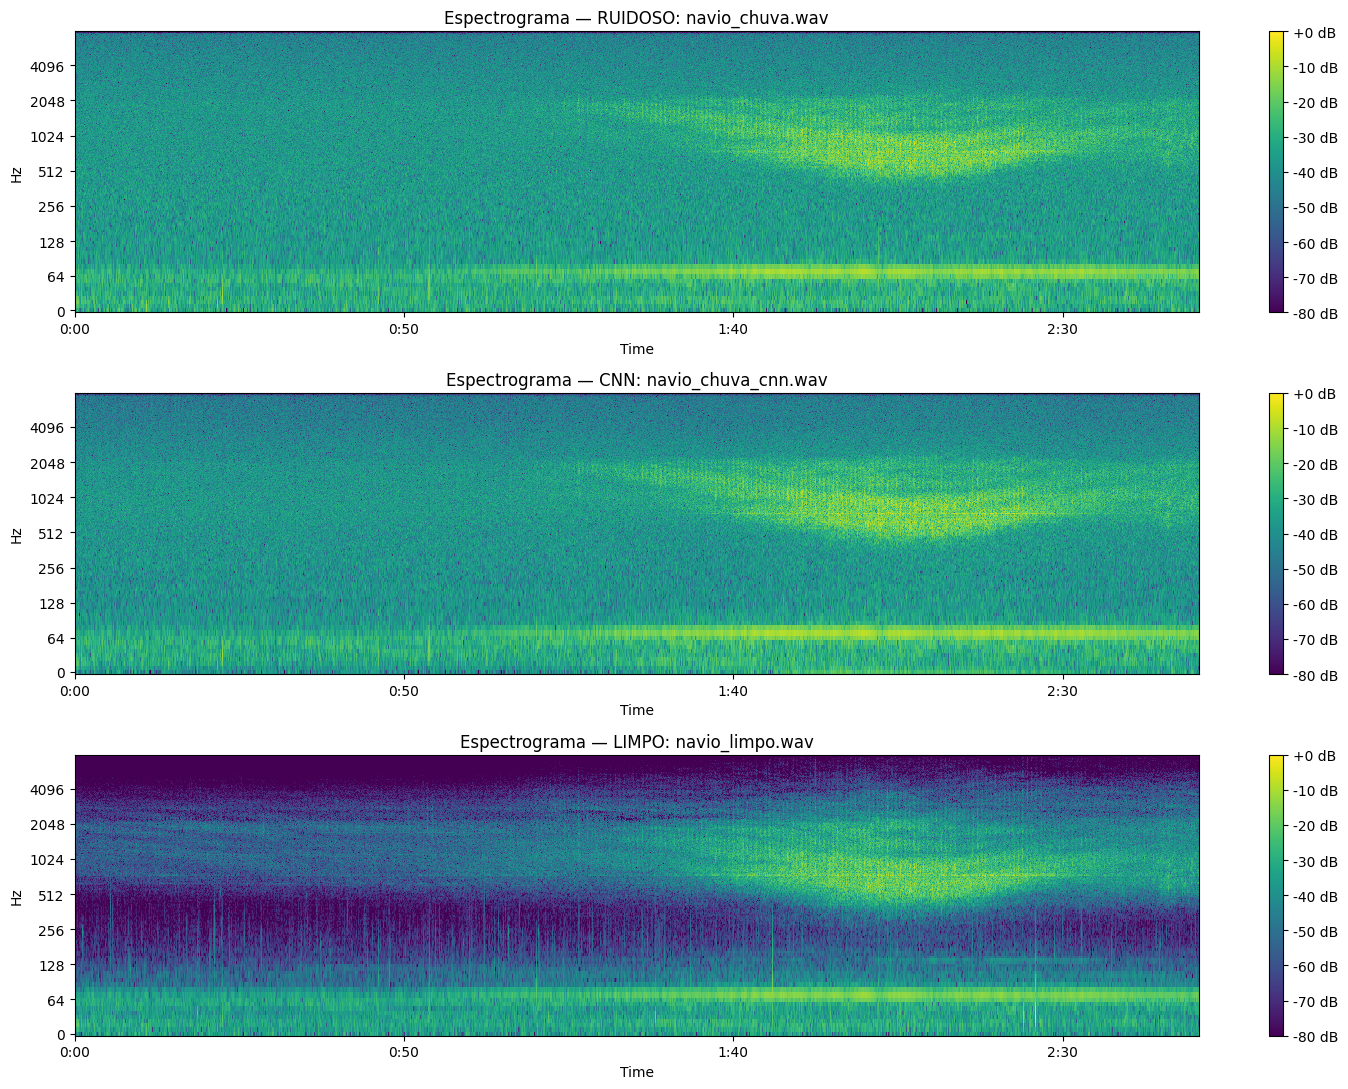

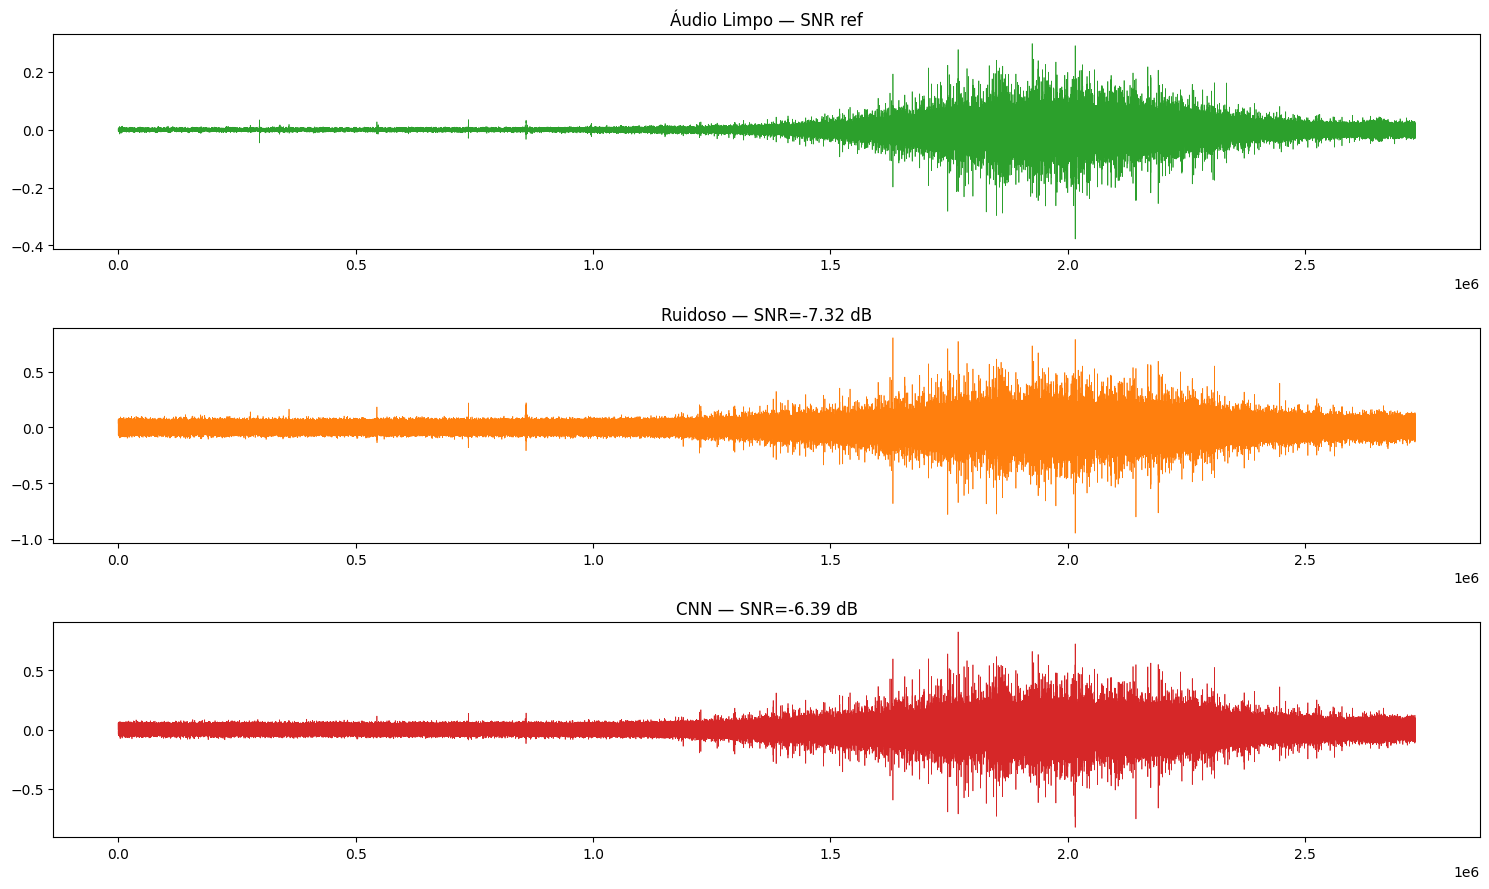


MÉDIA GERAL — CNN — 1 áudio(s) processado(s)
Métrica                            Ruidoso        Processado          Ganho
SNR (dB)                         -7.3163         -6.3942     +   0.9221
SNRseg (dB)                     -13.4789        -11.8552     +   1.6237
MSE                               0.0015          0.0012     -   0.0003
RMSE                              0.0392          0.0353     -   0.0040
SDR (dB)                          1.1398          1.6408     +   0.5010
SI-SDR (dB)                       1.1398          1.6408     +   0.5010
Pearson (r)                       0.7518          0.7704     +   0.0186

📦 ZIP gerado com 1 arquivo(s): /content/denoised_wavs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [4]:
# ==========================================================================
# INSTALAÇÃO
# ==========================================================================
!pip install -q librosa soundfile matplotlib pandas

# ==========================================================================
# IMPORTS
# ==========================================================================
import os, zipfile
import numpy as np
import librosa
import librosa.display
import soundfile as sf
import matplotlib.pyplot as plt
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers, models
from google.colab import files

# ==========================================================================
# CONFIGURAÇÕES
# ==========================================================================
SR = 16000
DURACAO_SEG = 2.0
SEG_LEN = int(SR * DURACAO_SEG)
RMS_ALVO = 0.1
EPS = 1e-10

OUT_DIR = "/content/denoised"
os.makedirs(OUT_DIR, exist_ok=True)

# ==========================================================================
# 1. UPLOAD DO MODELO CNN TREINADO
# ==========================================================================
print(">>> Faça upload do MODELO CNN treinado (.keras)")
uploaded_model = files.upload()
model_filename = list(uploaded_model.keys())[0]
with open(model_filename, 'wb') as f:
    f.write(uploaded_model[model_filename])
print(f"Modelo recebido: {model_filename}")

# ==========================================================================
# 2. UPLOAD DOS ÁUDIOS RUIDOSOS
# ==========================================================================
print("\n>>> Faça upload dos áudios RUIDOSOS (.wav)")
uploaded_noisy = files.upload()
noisy_files = list(uploaded_noisy.keys())
print("Áudios ruidosos:", noisy_files)

# ==========================================================================
# 3. UPLOAD DOS ÁUDIOS LIMPOS (referência)
# ==========================================================================
print("\n>>> Faça upload dos áudios LIMPOS de referência (.wav)")
uploaded_clean = files.upload()
clean_files = list(uploaded_clean.keys())
print("Áudios limpos:", clean_files)

# ==========================================================================
# ARQUITETURA CNN 1D (U-NET 1D) — idêntica à do treino
# ==========================================================================
def build_cnn1d_denoiser(input_len=SEG_LEN):
    inputs = layers.Input(shape=(input_len, 1))
    c1 = layers.Conv1D(32, 15, padding='same', activation='relu')(inputs)
    c1 = layers.Conv1D(32, 15, padding='same', activation='relu')(c1)
    p1 = layers.MaxPool1D(2)(c1)
    c2 = layers.Conv1D(64, 11, padding='same', activation='relu')(p1)
    c2 = layers.Conv1D(64, 11, padding='same', activation='relu')(c2)
    p2 = layers.MaxPool1D(2)(c2)
    c3 = layers.Conv1D(128, 9, padding='same', activation='relu')(p2)
    c3 = layers.Conv1D(128, 9, padding='same', activation='relu')(c3)
    p3 = layers.MaxPool1D(2)(c3)
    c4 = layers.Conv1D(256, 7, padding='same', activation='relu')(p3)
    c4 = layers.Conv1D(256, 7, padding='same', activation='relu')(c4)
    p4 = layers.MaxPool1D(2)(c4)
    c5 = layers.Conv1D(512, 5, padding='same', activation='relu')(p4)
    c5 = layers.Conv1D(512, 5, padding='same', activation='relu')(c5)
    u6 = layers.UpSampling1D(2)(c5); u6 = layers.Concatenate()([u6, c4])
    c6 = layers.Conv1D(256, 7, padding='same', activation='relu')(u6)
    c6 = layers.Conv1D(256, 7, padding='same', activation='relu')(c6)
    u7 = layers.UpSampling1D(2)(c6); u7 = layers.Concatenate()([u7, c3])
    c7 = layers.Conv1D(128, 9, padding='same', activation='relu')(u7)
    c7 = layers.Conv1D(128, 9, padding='same', activation='relu')(c7)
    u8 = layers.UpSampling1D(2)(c7); u8 = layers.Concatenate()([u8, c2])
    c8 = layers.Conv1D(64, 11, padding='same', activation='relu')(u8)
    c8 = layers.Conv1D(64, 11, padding='same', activation='relu')(c8)
    u9 = layers.UpSampling1D(2)(c8); u9 = layers.Concatenate()([u9, c1])
    c9 = layers.Conv1D(32, 15, padding='same', activation='relu')(u9)
    c9 = layers.Conv1D(32, 15, padding='same', activation='relu')(c9)
    outputs = layers.Conv1D(1, 15, padding='same', activation='linear')(c9)
    return models.Model(inputs, outputs, name="CNN1D_Denoiser")

def custom_loss(y_true, y_pred):
    mse_loss = tf.reduce_mean(tf.square(y_true - y_pred))
    mae_loss = tf.reduce_mean(tf.abs(y_true - y_pred))
    return mse_loss + 0.1 * mae_loss

# ==========================================================================
# CARREGAR O MODELO
# ==========================================================================
print("\n>>> Carregando modelo CNN...")
try:
    model = tf.keras.models.load_model(
        model_filename,
        custom_objects={'custom_loss': custom_loss},
        compile=False)
    model.compile(optimizer='adam', loss=custom_loss)
    print("✅ Modelo carregado com sucesso (.keras completo).")
except Exception as e:
    print(f"Falha ao carregar direto ({e}). Tentando reconstruir a arquitetura...")
    model = build_cnn1d_denoiser()
    model.load_weights(model_filename)
    model.compile(optimizer='adam', loss=custom_loss)
    print("✅ Pesos carregados na arquitetura reconstruída.")

# ==========================================================================
# FUNÇÕES AUXILIARES
# ==========================================================================
def rms(x):
    return float(np.sqrt(np.mean(x ** 2) + EPS))

# ==========================================================================
# DENOISING POR SEGMENTAÇÃO COM A CNN (mesma lógica do treino)
# ==========================================================================
def denoisar_audio_segmentado(limpo_path, ruidoso_path, model,
                              sr=SR, seg_len=SEG_LEN,
                              rms_silencio_db=-35.0, batch_size=32):
    clean_raw, _ = librosa.load(limpo_path, sr=sr, mono=True)
    noisy_raw, _ = librosa.load(ruidoso_path, sr=sr, mono=True)
    n = min(len(clean_raw), len(noisy_raw))
    clean_raw = clean_raw[:n].astype(np.float32)
    noisy_raw = noisy_raw[:n].astype(np.float32)

    pico_noisy = np.max(np.abs(noisy_raw)) + 1e-9
    clean_ref = clean_raw * (0.95 / pico_noisy)
    noisy_ref = noisy_raw * (0.95 / pico_noisy)

    if n < seg_len:
        pad = seg_len - n
        noisy_ref = np.pad(noisy_ref, (0, pad))
        clean_ref = np.pad(clean_ref, (0, pad))
        n_proc = seg_len
    else:
        n_proc = n

    hop = seg_len // 2
    starts = list(range(0, n_proc - seg_len + 1, hop))
    if starts[-1] + seg_len < n_proc:
        starts.append(n_proc - seg_len)

    rms_global = rms(noisy_ref)
    limiar_silencio = rms_global * (10 ** (rms_silencio_db / 20))

    preds = np.zeros((len(starts), seg_len), dtype=np.float32)
    rms_por_janela = np.zeros(len(starts), dtype=np.float32)

    segmentos_norm, indices_validos = [], []
    for i, s in enumerate(starts):
        seg = noisy_ref[s:s + seg_len]
        r = rms(seg)
        if r < limiar_silencio:
            continue
        rms_por_janela[i] = r
        segmentos_norm.append(seg * (RMS_ALVO / (r + 1e-12)))
        indices_validos.append(i)

    if indices_validos:
        X = np.stack(segmentos_norm, axis=0)[..., np.newaxis].astype(np.float32)
        y_pred = model.predict(X, batch_size=batch_size, verbose=0).squeeze(-1)
        y_pred = np.clip(y_pred, -1.0, 1.0)
        for k, idx in enumerate(indices_validos):
            preds[idx] = y_pred[k] * (rms_por_janela[idx] / RMS_ALVO)

    denoised = np.zeros(n_proc, dtype=np.float32)
    window_sum = np.zeros(n_proc, dtype=np.float32)
    window = np.hanning(seg_len).astype(np.float32)

    for i, s in enumerate(starts):
        denoised[s:s + seg_len] += preds[i] * window
        window_sum[s:s + seg_len] += window
    denoised /= (window_sum + 1e-8)

    return clean_ref[:n], noisy_ref[:n], denoised[:n]

# ==========================================================================
# MÉTRICAS
# ==========================================================================
def _align(ref, est):
    n = min(len(ref), len(est))
    return ref[:n], est[:n]

def snr(ref, est):
    ref, est = _align(ref, est)
    noise = ref - est
    num = np.sum(ref ** 2)
    den = np.sum(noise ** 2) + 1e-12
    return 10 * np.log10(num / den)

def snr_seg(ref, est, sr, frame_len=0.02, hop=0.01):
    ref, est = _align(ref, est)
    fl = int(frame_len * sr); hp = int(hop * sr)
    if fl <= 0 or len(ref) < fl:
        return snr(ref, est)
    vals = []
    for s in range(0, len(ref) - fl, hp):
        r = ref[s:s + fl]; e = est[s:s + fl]
        noise = r - e
        num = np.sum(r ** 2); den = np.sum(noise ** 2) + 1e-12
        v = 10 * np.log10(num / den)
        if np.isfinite(v):
            vals.append(v)
    return float(np.mean(vals)) if vals else np.nan

def mse(ref, est):
    ref, est = _align(ref, est)
    return float(np.mean((ref - est) ** 2))

def rmse(ref, est):
    return float(np.sqrt(mse(ref, est)))

def sdr(ref, est):
    ref, est = _align(ref, est)
    ref = ref.astype(np.float64); est = est.astype(np.float64)
    denom = np.dot(ref, ref) + 1e-12
    alpha = np.dot(ref, est) / denom
    s_target = alpha * ref
    e_res = est - s_target
    num = np.sum(s_target ** 2)
    den = np.sum(e_res ** 2) + 1e-12
    return 10 * np.log10(num / den)

def si_sdr(ref, est):
    return sdr(ref, est)

def pearson(ref, est):
    ref, est = _align(ref, est)
    ref = ref.astype(np.float64); est = est.astype(np.float64)
    if np.std(ref) < 1e-12 or np.std(est) < 1e-12:
        return np.nan
    return float(np.corrcoef(ref, est)[0, 1])

# ==========================================================================
# MATCH RUIDOSO ↔ LIMPO
# ==========================================================================
def encontrar_par(noisy_name, clean_files):
    base = noisy_name.rsplit('.', 1)[0]
    candidates = [
        base.replace('chuva', 'limpo'),
        base.replace('ruido', 'limpo'),
        base.replace('ruído', 'limpo'),
        base.replace('_noisy', '_clean'),
        base.replace('_noise', '_clean'),
        base.replace('_n', '_l'),
    ]
    for c in clean_files:
        stem = c.rsplit('.', 1)[0]
        if stem in candidates or stem == base:
            return c
    prefix = base.split('_')[0]
    for c in clean_files:
        if c.rsplit('.', 1)[0].split('_')[0] == prefix:
            return c
    return None

# ==========================================================================
# IMPRESSÃO DA TABELA (formato solicitado)
# ==========================================================================
ORDEM_METRICAS = [
    ("SNR (dB)",      "SNR Ruidoso (dB)",   "SNR CNN (dB)"),
    ("SNRseg (dB)",   "SNRseg Ruidoso (dB)","SNRseg CNN (dB)"),
    ("MSE",           "MSE Ruidoso",        "MSE CNN"),
    ("RMSE",          "RMSE Ruidoso",       "RMSE CNN"),
    ("SDR (dB)",      "SDR Ruidoso (dB)",   "SDR CNN (dB)"),
    ("SI-SDR (dB)",   "SI-SDR Ruidoso (dB)","SI-SDR CNN (dB)"),
    ("Pearson (r)",   "Pearson Ruidoso",    "Pearson CNN"),
]

def _fmt(v):
    if v is None or (isinstance(v, float) and np.isnan(v)):
        return "   nan"
    return f"{v:>10.4f}"

def _fmt_gain(v):
    if v is None or (isinstance(v, float) and np.isnan(v)):
        return "   nan"
    sign = "+" if v >= 0 else "-"
    return f"{sign}{abs(v):>9.4f}"

def imprimir_tabela(titulo, linhas):
    print("\n" + "=" * 80)
    print(titulo)
    print("=" * 80)
    print(f"{'Métrica':<28}{'Ruidoso':>14}{'Processado':>18}{'Ganho':>15}")
    print("=" * 80)
    for nome, r, p in linhas:
        g = (p - r) if (r is not None and p is not None
                        and not (isinstance(r, float) and np.isnan(r))
                        and not (isinstance(p, float) and np.isnan(p))) else np.nan
        print(f"{nome:<28}{_fmt(r):>12}{_fmt(p):>16}{_fmt_gain(g):>15}")
    print("=" * 80)

# ==========================================================================
# PROCESSAMENTO
# ==========================================================================
resultados = []
caminhos_salvos = []

for noisy_name in noisy_files:
    clean_name = encontrar_par(noisy_name, clean_files)
    if clean_name is None:
        print(f"[AVISO] Sem referência limpa para {noisy_name}. Pulando.")
        continue

    print(f"\n>>> Processando: {noisy_name}  (ref: {clean_name})")
    print("    Processando CNN...")

    clean_ref, noisy_ref, den_cnn = denoisar_audio_segmentado(
        clean_name, noisy_name, model)

    n = min(len(clean_ref), len(noisy_ref), len(den_cnn))
    clean_ref = clean_ref[:n]
    noisy_ref = noisy_ref[:n]
    den_cnn   = den_cnn[:n]

    # ----- SALVAR ÁUDIO DENOISED -----
    out_name = noisy_name.rsplit('.', 1)[0] + '_cnn.wav'
    out_path = os.path.join(OUT_DIR, out_name)
    sf.write(out_path, den_cnn, SR)
    caminhos_salvos.append(out_path)
    print(f"    💾 Salvo: {out_path}")

    # ----- MÉTRICAS -----
    row = {
        'Áudio'              : noisy_name,
        'SNR Ruidoso (dB)'   : snr(clean_ref, noisy_ref),
        'SNRseg Ruidoso (dB)': snr_seg(clean_ref, noisy_ref, SR),
        'MSE Ruidoso'        : mse(clean_ref, noisy_ref),
        'RMSE Ruidoso'       : rmse(clean_ref, noisy_ref),
        'SDR Ruidoso (dB)'   : sdr(clean_ref, noisy_ref),
        'SI-SDR Ruidoso (dB)': si_sdr(clean_ref, noisy_ref),
        'Pearson Ruidoso'    : pearson(clean_ref, noisy_ref),
        'SNR CNN (dB)'       : snr(clean_ref, den_cnn),
        'SNRseg CNN (dB)'    : snr_seg(clean_ref, den_cnn, SR),
        'MSE CNN'            : mse(clean_ref, den_cnn),
        'RMSE CNN'           : rmse(clean_ref, den_cnn),
        'SDR CNN (dB)'       : sdr(clean_ref, den_cnn),
        'SI-SDR CNN (dB)'    : si_sdr(clean_ref, den_cnn),
        'Pearson CNN'        : pearson(clean_ref, den_cnn),
    }
    resultados.append(row)

    # ----- TABELA INDIVIDUAL -----
    linhas_individuais = [
        (nome, row[col_r], row[col_p])
        for nome, col_r, col_p in ORDEM_METRICAS
    ]
    imprimir_tabela(f"ÁUDIO: {noisy_name}   (ref: {clean_name}) — CNN", linhas_individuais)

    # ----- GRÁFICO COMPARATIVO (3 espectrogramas) -----
    fig, axes = plt.subplots(3, 1, figsize=(15, 11))

    S_noisy = librosa.amplitude_to_db(np.abs(librosa.stft(noisy_ref)), ref=np.max)
    S_cnn   = librosa.amplitude_to_db(np.abs(librosa.stft(den_cnn)),   ref=np.max)
    S_ref   = librosa.amplitude_to_db(np.abs(librosa.stft(clean_ref)), ref=np.max)

    img0 = librosa.display.specshow(S_noisy, sr=SR, x_axis='time',
                                    y_axis='log', cmap='viridis', ax=axes[0])
    axes[0].set_title(f'Espectrograma — RUIDOSO: {noisy_name}')
    fig.colorbar(img0, ax=axes[0], format='%+2.0f dB')

    img1 = librosa.display.specshow(S_cnn, sr=SR, x_axis='time',
                                    y_axis='log', cmap='viridis', ax=axes[1])
    axes[1].set_title(f'Espectrograma — CNN: {out_name}')
    fig.colorbar(img1, ax=axes[1], format='%+2.0f dB')

    img2 = librosa.display.specshow(S_ref, sr=SR, x_axis='time',
                                    y_axis='log', cmap='viridis', ax=axes[2])
    axes[2].set_title(f'Espectrograma — LIMPO: {clean_name}')
    fig.colorbar(img2, ax=axes[2], format='%+2.0f dB')

    plt.tight_layout()
    plt.show()

    # ----- GRÁFICO DAS FORMAS DE ONDA -----
    fig2, axes2 = plt.subplots(3, 1, figsize=(15, 9))
    axes2[0].plot(clean_ref, linewidth=0.5, color='tab:green')
    axes2[0].set_title(f'Áudio Limpo — SNR ref')
    axes2[1].plot(noisy_ref, linewidth=0.5, color='tab:orange')
    axes2[1].set_title(f'Ruidoso — SNR={row["SNR Ruidoso (dB)"]:.2f} dB')
    axes2[2].plot(den_cnn, linewidth=0.5, color='tab:red')
    axes2[2].set_title(f'CNN — SNR={row["SNR CNN (dB)"]:.2f} dB')
    plt.tight_layout()
    plt.show()

# ==========================================================================
# TABELA FINAL — MÉDIA DE TODOS OS ÁUDIOS
# ==========================================================================
if resultados:
    df = pd.DataFrame(resultados)
    medias = df.drop(columns=['Áudio']).mean()

    linhas_media = [
        (nome, medias[col_r], medias[col_p])
        for nome, col_r, col_p in ORDEM_METRICAS
    ]
    imprimir_tabela(
        f"MÉDIA GERAL — CNN — {len(df)} áudio(s) processado(s)",
        linhas_media
    )

# ==========================================================================
# ZIP + DOWNLOAD
# ==========================================================================
if caminhos_salvos:
    zip_path = "/content/denoised_wavs.zip"
    with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as zf:
        for p in caminhos_salvos:
            zf.write(p, arcname=os.path.basename(p))
    print(f"\n📦 ZIP gerado com {len(caminhos_salvos)} arquivo(s): {zip_path}")
    try:
        files.download(zip_path)
    except Exception as e:
        print(f"[Aviso] Download automático falhou: {e}")
else:
    print("\n[AVISO] Nenhum áudio denoised foi salvo.")